In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ["XLA_PYTHON_CLIENT_MEM_FRACTION"] = "0.95"

In [3]:
import matplotlib.pyplot as plt
%matplotlib inline
import jax
import jax.numpy as jnp
import jax.random as jr
import optax
import math
jax.config.update("jax_debug_nans", True)

import k3d
import numpy as np
from matplotlib.colors import ListedColormap
from typing import Callable
from functools import partial

from implicitSurfaces.lipschitzImplicit import sdfImplicit
from implicitSurfaces.harmonicImplicit import poissonSurface
from implicitSurfaces.sdf_primitives import sphere_sdf, bbox_sdf, arc2d
from sphereWalker.integrator import WoSIntegrator, DifferentialWoSIntegrator
from sphereWalker.sampling import sample_uniform_1sphere
from utils.losses import volume_integral_loss_grad, surface_integral_loss_grad, l2_loss, dL2_du, surface_integral_loss_grad_normalized
from utils.tree_ops import binary_tree_op, accumulate_weighted_trees
import operator
from utils.helpers import mesh_2d

In [18]:
def const_source_fn(x):
    return 4.0

def zero_boundary_condition(point: jnp.ndarray) -> jnp.ndarray:
    return 0.0

In [21]:
params_to_opt = {'radius': jnp.array(1.0)}
fn_to_opt = lambda params, x: sphere_sdf({**params, 'center': jnp.array([0.0, 0.0])}, x)
outer_boundary = lambda params, x: sphere_sdf({'center': jnp.array([0.0000, 0.0000]), 'radius': jnp.array(1.5)}, x)
composed_field_fn = lambda p, x: jnp.maximum(-fn_to_opt(p, x), outer_boundary(p, x))
target_surface_fn = lambda p, x: jnp.maximum(-sphere_sdf({'center': jnp.array([0.0, 0.0]), 'radius': jnp.array(0.3)}, x), outer_boundary(p, x))
surface_to_opt = sdfImplicit(fn=composed_field_fn, dim=2)
target_surface = sdfImplicit(fn=target_surface_fn, dim=2)

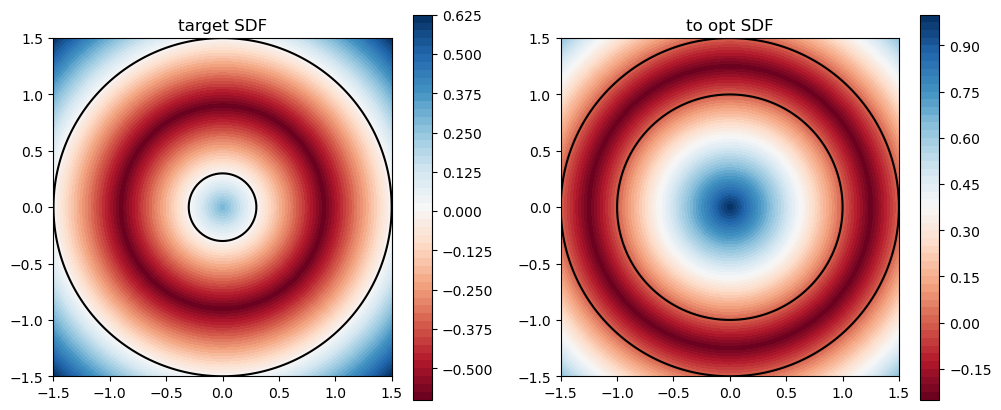

In [22]:
X, Y = mesh_2d(128, ((-1.5, 1.5), (-1.5, 1.5)))
points = jnp.stack([X, Y], axis=-1).reshape(-1, 2)


fig = plt.figure(figsize=(12, 5))
ax1 = fig.add_subplot(121)
contouf = ax1.contourf(X, Y, jax.vmap(target_surface)(None, points).reshape(X.shape), levels=50, cmap='RdBu')
contour = ax1.contour(X, Y, jax.vmap(target_surface)(None, points).reshape(X.shape), levels=[0.0], colors='k')
ax1.set_aspect('equal')
ax1.set_title('target SDF')
plt.colorbar(contouf)

ax2 = fig.add_subplot(122)
contouf2 = ax2.contourf(X, Y, jax.vmap(surface_to_opt, in_axes=(None, 0))(params_to_opt, points).reshape(X.shape), levels=50, cmap='RdBu')
contour2 = ax2.contour(X, Y, jax.vmap(surface_to_opt, in_axes=(None, 0))(params_to_opt, points).reshape(X.shape), levels=[0.0], colors='k')
ax2.set_aspect('equal')
ax2.set_title('to opt SDF')
plt.colorbar(contouf2)


plt.show()

In [23]:
key = jax.random.PRNGKey(0)
N = 10000

reference_solver = WoSIntegrator(
    empty_sphere_fn=target_surface.empty_sphere, 
    boundary_condition_fn=zero_boundary_condition,
    source_term_fn=const_source_fn,
    dim=2,
    level_set=0.0,
    eps=1e-3,
    max_steps=1000,
    print_progress=False
)

inside_reference_mask = jax.vmap(target_surface)(None, points) < 0
reference_estimate = reference_solver.integrate_batch(None, points[inside_reference_mask], rng_key=jax.random.PRNGKey(2), init_trust_region_size=jnp.inf, n_samples=512)
reference_estimate_full = jnp.zeros((points.shape[0], 1))
reference_estimate_full = reference_estimate_full.at[inside_reference_mask].set(reference_estimate.w)

In [24]:
dif_integrator = DifferentialWoSIntegrator(
    empty_sphere_fn=surface_to_opt.empty_sphere, 
    boundary_condition_fn=zero_boundary_condition,
    source_term_fn=const_source_fn,
    Df=surface_to_opt.dirichlet_boundary_differential,
    V_n=surface_to_opt.normal_surface_velocity,
    normal_fn=surface_to_opt.normal_at,
    offset_l=0.01,
    dim=surface_to_opt.dim,
    level_set=surface_to_opt.level_set,
    eps=1e-3,
    max_steps=1000,
)

primary_integrator = WoSIntegrator(
    empty_sphere_fn=surface_to_opt.empty_sphere, 
    boundary_condition_fn=zero_boundary_condition,
    source_term_fn=const_source_fn,
    dim=surface_to_opt.dim,
    level_set=surface_to_opt.level_set,
    eps=1e-3,
    max_steps=1000,
    print_progress=False
)

In [25]:
init_inside = jax.vmap(surface_to_opt, in_axes=(None, 0))(params_to_opt, points) < surface_to_opt.level_set
init_estimate = primary_integrator.integrate_batch(params_to_opt, points[init_inside], rng_key=jax.random.PRNGKey(2), init_trust_region_size=jnp.inf, n_samples=512)
init_estimate_full = jnp.zeros((points.shape[0], 1))
init_estimate_full = init_estimate_full.at[init_inside].set(init_estimate.w)

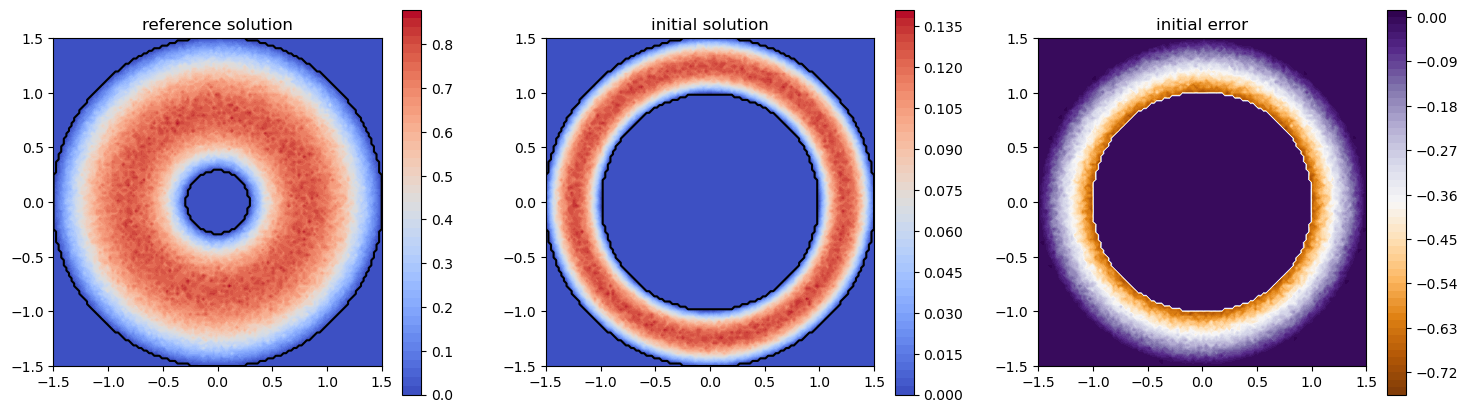

In [38]:
fig = plt.figure(figsize=(18, 5))
ax1 = fig.add_subplot(131)
contouf = ax1.contourf(X, Y, reference_estimate_full.reshape(X.shape), levels=50, cmap='coolwarm')
contour = ax1.contour(X, Y, reference_estimate_full.reshape(X.shape), levels=[0.0], colors='k')
ax1.set_aspect('equal')
ax1.set_title('reference solution')
plt.colorbar(contouf)

ax2 = fig.add_subplot(132)
contouf2 = ax2.contourf(X, Y, init_estimate_full.reshape(X.shape), levels=50, cmap='coolwarm')
contour2 = ax2.contour(X, Y, init_estimate_full.reshape(X.shape), levels=[0.0], colors='k')
ax2.set_aspect('equal')
ax2.set_title('initial solution')
plt.colorbar(contouf2)

ax3 = fig.add_subplot(133)
error = jnp.zeros_like(reference_estimate_full)
error = error.at[init_inside].set((init_estimate_full - reference_estimate_full)[init_inside])
contouf3 = ax3.contourf(X, Y, error.reshape(X.shape), levels=50, cmap='PuOr')
contour3 = ax3.contour(X, Y, error.reshape(X.shape), levels=[0.1], colors='k')
ax3.set_aspect('equal')
ax3.set_title('initial error')
plt.colorbar(contouf3)

### Analytical stuff:

Let $\Omega$ be the annulus defined by $R_{min} < r < R_{max}$. We consider the Poisson equation with a constant source term $S$ (constant source) and homogeneous Dirichlet boundary conditions:

\begin{equation}
    \begin{cases}
        -\Delta u = S & \text{in } \Omega \\
        u = 0 & \text{on } \partial \Omega
    \end{cases}
\end{equation}

Assuming radial symmetry where $u = u(r)$, the Laplacian in polar coordinates simplifies to:
\begin{equation}
    -\frac{1}{r} \frac{d}{dr} \left( r \frac{du}{dr} \right) = S
\end{equation}

##### Derivation
Integrating the differential equation twice with respect to $r$:

\begin{align}
    \frac{d}{dr} \left( r \frac{du}{dr} \right) &= -S r \\
    r \frac{du}{dr} &= -\frac{S}{2}r^2 + C_1 \\
    \frac{du}{dr} &= -\frac{S}{2}r + \frac{C_1}{r} \\
    u(r) &= -\frac{S}{4}r^2 + C_1 \ln(r) + C_2
\end{align}

We determine the integration constants $C_1$ and $C_2$ using the boundary conditions $u(R_{min}) = 0$ and $u(R_{max}) = 0$:

\begin{equation}
    \begin{cases}
        -\frac{S}{4}R_{min}^2 + C_1 \ln(R_{min}) + C_2 = 0 \\
        -\frac{S}{4}R_{max}^2 + C_1 \ln(R_{max}) + C_2 = 0
    \end{cases}
\end{equation}

Subtracting the first equation from the second eliminates $C_2$:
\begin{equation}
    -\frac{S}{4}(R_{max}^2 - R_{min}^2) + C_1 (\ln(R_{max}) - \ln(R_{min})) = 0
\end{equation}

Solving for $C_1$:
\begin{equation}
    C_1 = \frac{S}{4} \frac{R_{max}^2 - R_{min}^2}{\ln(R_{max}/R_{min})}
\end{equation}

Using the boundary condition at $R_{max}$ to solve for $C_2$:
\begin{equation}
    C_2 = \frac{S}{4}R_{max}^2 - C_1 \ln(R_{max})
\end{equation}

##### Final Solution
Substituting $C_1$ and $C_2$ back into the eq. and simplifying:

\begin{equation}
    u(r) = \frac{S}{4} \left[ (R_{max}^2 - r^2) - \frac{R_{max}^2 - R_{min}^2}{\ln(R_{max}/R_{min})} \ln\left(\frac{R_{max}}{r}\right) \right]
\end{equation}


##### Derivative wrt. $R_{min}$

\begin{equation}
    \frac{\partial u}{\partial R_{min}}(r) = \frac{S}{4}\ln{\frac{R_{max}}{r}} \left[ \frac{2 R_{min}}{\ln(\frac{R_{max}}{R_{min}})} - \frac{R_{max}^2-R_{min}^2}{\ln(\frac{R_{max}}{R_{min}})^2 R_{min}} \right]
\end{equation}

##### Loss

\begin{equation}
L(R_{min}) = \int_{\Omega(R_{min})} \frac{1}{2}(u(R_{min}, x) - u_{target}(x))^2 dV
\end{equation}

##### Loss gradient

\begin{equation}
\frac{\partial L}{\partial R_{min}}(R_{min}) = \int_{\Omega(R_{min})} (u(R_{min}, x) - u_{target}(x)) \frac{\partial u}{\partial R_{min}}(R_{min}, x) dV + \int_{\partial \Omega(R_{min})} \frac{1}{2}(u(R_{min}, x) - u_{target}(x))^2 (V_{implicit}(R_{min}, x) \cdot \hat{n}) dA
\end{equation}

The unit normal vector pointing outward from the level set $\phi < 0$ (towards $\phi > 0$) is given by:
\begin{equation}
    \hat{n} = \frac{\nabla_x \phi}{\|\nabla_x \phi\|}
\end{equation}
We assume $\hat{n}$ is the outward normal from the domain material. Care must be taken with the sign convention of $\phi$.

##### Application to the Annulus Inner Radius
Consider the annulus domain defined by $R_{min} < \|x\| < R_{max}$.
The inner boundary is the interface between the material ($r > R_{min}$) and the void ($r < R_{min}$).

We define the implicit function $\phi(x, R_{min})$ such that $\phi < 0$ inside the domain (material) and $\phi = 0$ on the boundary:
\begin{equation}
    \phi(x, R_{min}) = R_{min} - \|x\|
\end{equation}

Now we apply this with $p = R_{min}$:

\begin{equation}
    \nabla_x \phi = \nabla_x (R_{min} - \|x\|) = - \frac{x}{\|x\|} = -\hat{r}
\end{equation}
The magnitude is:
\begin{equation}
    \|\nabla_x \phi\| = \|-\hat{r}\| = 1
\end{equation}
The normal vector $\hat{n}$ pointing out of the domain (into the hole) is:
\begin{equation}
    \hat{n} = \frac{-\hat{r}}{1} = -\hat{r}
\end{equation}

\begin{equation}
    \frac{\partial \phi}{\partial R_{min}} = \frac{\partial}{\partial R_{min}}(R_{min} - \|x\|) = 1
\end{equation}

Substitute terms into the general formula:
\begin{equation}
    V_n = - \frac{1}{1} = -1
\end{equation}

##### Computation of the Surface Integral Term

We wish to evaluate the boundary sensitivity term $J_{\Gamma}$ arising from the shape derivative of the squared error loss function:

\begin{equation}
    J_{\Gamma} = \int_{\partial \Omega(R_{min})} \frac{1}{2}\left( u(x) - u_{target}(x) \right)^2 (V_{implicit} \cdot \hat{n}) \, dA
\end{equation}

##### 1. Geometric Setup
The domain boundary $\partial \Omega$ consists of two parts: the inner circle at $r = R_{min}$ and the outer circle at $r = R_{max}$. Since we are only optimizing $R_{min}$, the velocity $V_{implicit}$ is zero on the outer boundary. We restrict our integration to the inner boundary $\Gamma_{in}$.

- Radius: $r = R_{min}$
- Differential Arc Length ($dA$): In polar coordinates, $dA = R_{min} \, d\theta$
- Integration Limits: $\theta \in [0, 2\pi]$
- Normal Velocity ($V_n$): As derived previously, $V_n = V_{implicit} \cdot \hat{n} = -1$.

##### 2. Substitution
Substituting these terms into the integral:

\begin{equation}
    J_{\Gamma} = \int_{0}^{2\pi} \frac{1}{2} \left( u(R_{min}, \theta) - u_{target}(R_{min}, \theta) \right)^2 (-1) \, (R_{min} \, d\theta)
\end{equation}

Rearranging constants:
\begin{equation}
    J_{\Gamma} = - \frac{R_{min}}{2} \int_{0}^{2\pi} \left( u(R_{min}, \theta) - u_{target}(R_{min}, \theta) \right)^2 \, d\theta
\end{equation}

##### 3. Evaluation under Radial Symmetry
If the source term and boundary conditions are radially symmetric (independent of $\theta$), then the solution $u(r)$ and target $u_{target}(r)$ are constant along the circle $r = R_{min}$.
Let $L(R_{min}) = (u(R_{min}) - u_{target}(R_{min}))^2$.

The integral simplifies to:
\begin{equation}
    J_{\Gamma} = - \frac{R_{min}}{2} \cdot L(R_{min}) \cdot \int_{0}^{2\pi} d\theta
\end{equation}

\begin{equation}
    J_{\Gamma} = - \frac{R_{min}}{2} \cdot L(R_{min}) \cdot 2\pi
\end{equation}

\begin{equation}
    \boxed{ J_{\Gamma} = - \pi R_{min} \left( u(R_{min}) - u_{target}(R_{min}) \right)^2 }
\end{equation}

We now derive the volume contribution $J_{\Omega}$ to the total shape gradient. This term accounts for how the solution $u(r)$ itself changes throughout the domain as the parameter $R_{min}$ is perturbed.

\begin{equation}
    J_{\Omega} = \int_{\Omega(R_{min})} \frac{\partial L}{\partial u} \frac{\partial u}{\partial R_{min}} \, dV
\end{equation}

Substituting the components into the integral over the annulus $\Omega = \{(r, \theta) : R_{min} < r < R_{max}, 0 \le \theta < 2\pi\}$:

\begin{equation}
    J_{\Omega} = \int_{0}^{2\pi} \int_{R_{min}}^{R_{max}} \left( u(r) - u_{target}(r) \right) \left( \frac{\partial u}{\partial R_{min}} \right) r \, dr \, d\theta
\end{equation}

Since the problem is radially symmetric, the terms $(u - u_{target})$ and $\frac{\partial u}{\partial R_{min}}$ depend only on $r$, not on $\theta$. We can factor out the angular integration:

\begin{equation}
    \int_{0}^{2\pi} d\theta = 2\pi
\end{equation}

The volume term simplifies to a 1D radial integral:

\begin{equation}
    \boxed{ J_{\Omega} = 2\pi \int_{R_{min}}^{R_{max}} \left( u(r) - u_{target}(r) \right) \frac{\partial u(r)}{\partial R_{min}} \, r \, dr }
\end{equation}

add a volume penalty term to the total objective function.

Loss Formulation
We define a squared error penalty on the volume deviation from a target $V_{target}$:
\begin{equation}
    J_{vol}(\Omega) = \frac{1}{2} \lambda_{vol} \left( V(\Omega) - V_{target} \right)^2
\end{equation}


General Shape Derivative
We compute the derivative with respect to the shape parameter $p$ (e.g., $R_{min}$) using the chain rule:

\begin{equation}
    \frac{d J_{vol}}{d p} = \lambda_{vol} (V(\Omega) - V_{target}) \frac{d V}{d p}
\end{equation}

Using the Reynolds Transport Theorem, the derivative of the volume functional is simply the integral of the normal velocity $V_n$ over the boundary:

\begin{equation}
    \frac{d V}{d p} = \oint_{\partial \Omega} V_n \, dA
\end{equation}

Substituting this back:
\begin{equation}
    \frac{d J_{vol}}{d p} = \lambda_{vol} (V(\Omega) - V_{target}) \oint_{\partial \Omega} V_n \, dA
\end{equation}

For the annulus defined by $R_{min} < r < R_{max}$:

##### Volume Calculation

\begin{equation}
    V(\Omega) = \pi (R_{max}^2 - R_{min}^2)
\end{equation}

##### Volume Derivative (Analytical)
Differentiating directly with respect to $R_{min}$:
\begin{equation}
    \frac{d V}{d R_{min}} = \frac{d}{d R_{min}} [\pi R_{max}^2 - \pi R_{min}^2] = -2\pi R_{min}
\end{equation}

##### Verification via Surface Integral
We verify this matches the Reynolds Transport Theorem.

\begin{equation}
    \oint_{\Gamma_{in}} V_n \, dA = \int_{0}^{2\pi} (-1) R_{min} \, d\theta = -2\pi R_{min}
\end{equation}
(The results match.)

Substituting the derivative back into the chain rule equation:

\begin{equation}
    \boxed{ \frac{d J_{vol}}{d R_{min}} = -\lambda_{vol} \cdot 2\pi R_{min} \cdot \left[ \pi(R_{max}^2 - R_{min}^2) - V_{target} \right] }
\end{equation}

In [43]:
def l2_loss_density(u, u_target):
    """
    Local squared error density.
    dL/du = (u - u_target)
    """
    return 0.5 * (u - u_target)**2

In [42]:
def solution_analytical(R_min, R_max, const_source, x):
    r = jnp.linalg.norm(x)
    result = const_source(x)/4.0 * (R_max**2 - r**2 - jnp.log(R_max/r) * (R_max**2 - R_min**2)/jnp.log(R_max/R_min))
    return jnp.where(jnp.logical_and(r > R_min, r < R_max), result, 0.0)

def solution_Rmin_deriv(R_min, R_max, const_source, x):
    r = jnp.linalg.norm(x)
    log_term = jnp.log(R_max/R_min)
    result = const_source(x)/4.0 * jnp.log(R_max/r) * (2*R_min/log_term - (R_max**2 - R_min**2)/(R_min * log_term**2))
    return jnp.where(jnp.logical_and(r > R_min, r < R_max), result, 0.0)

In [50]:
def surface_integral_unnormalized(R_min_opt, R_min_target, R_max, const_source):
    """
    Computes the surface gradient contribution for Total Loss.
    Formula: Integral_boundary [ L(u) * V_n ] dA
    """
    # 1. Evaluate Local Loss at the boundary R_min
    # Because of radial symmetry, we only need to evaluate at one point (r=R_min)
    x_boundary = jnp.array([R_min_opt, 0.0])
    
    u_val = solution_analytical(R_min_opt, R_max, const_source, x_boundary)
    u_target_val = solution_analytical(R_min_target, R_max, const_source, x_boundary)
    
    loss_val = l2_loss_density(u_val, u_target_val)
    
    # 2. Geometry terms
    circumference = 2 * jnp.pi * R_min_opt
    Vn = -1.0  # Normal velocity (inward relative to domain)
    
    # 3. Surface Integral
    # Integral = L(R_min) * Circumference * Vn
    return loss_val * circumference * Vn


def volume_integral_unnormalized(R_min_opt, R_min_target, R_max, const_source):
    """
    Computes the volume gradient contribution for Total Loss.
    Formula: Integral_domain [ (u - u_target) * du/dR_min ] dV
    """
    # 1. Integration grid (Radial)
    r_vals = jnp.linspace(R_min_opt, R_max, 1000)
    
    # 2. Evaluate Fields across the domain
    # Current solution u(r)
    u_vals = jax.vmap(lambda r: solution_analytical(R_min_opt, R_max, const_source, jnp.array([r, 0.0])))(r_vals)
    
    # Target solution u_target(r)
    # Note: Target is fixed, but we evaluate it on the current grid
    u_target_vals = jax.vmap(lambda r: solution_analytical(R_min_target, R_max, const_source, jnp.array([r, 0.0])))(r_vals)
    
    # Shape Sensitivity du/dR_min(r)
    du_dR_vals = jax.vmap(lambda r: solution_Rmin_deriv(R_min_opt, R_max, const_source, jnp.array([r, 0.0])))(r_vals)
    
    # 3. Construct Integrand
    # Integrand = dL/du * du/dR * Jacobian(r)
    # dL/du = (u - u_target)
    integrand = (u_vals - u_target_vals) * du_dR_vals * r_vals
    
    # 4. Integrate
    # Trapezoid rule for radial part * 2pi for angular part
    return jnp.trapezoid(integrand, r_vals) * 2 * jnp.pi

In [51]:
def surface_integral_normalized(R_min_opt, R_min_target, R_max, const_source):
    """
    Computes the surface gradient contribution using the Normalized (Average Loss) formulation.
    Formula: (1/Vol) * Integral_boundary [ (Local_Loss - Average_Loss) * V_n ] dA
    """
    # 1. Geometry: Volume (Area) of the Annulus domain
    vol_annulus = jnp.pi * (R_max**2 - R_min_opt**2)
    
    # 2. Compute Total Energy / Average Loss (J_avg)
    # We integrate the loss density over the whole domain
    r_vals = jnp.linspace(R_min_opt, R_max, 1000)
    
    # Evaluate u and u_target across the radius
    # We use a dummy y=0 coordinate since solution is radially symmetric
    sol_opt = jax.vmap(lambda r: solution_analytical(R_min_opt, R_max, const_source, jnp.array([r, 0.0])))(r_vals)
    sol_target = jax.vmap(lambda r: solution_analytical(R_min_target, R_max, const_source, jnp.array([r, 0.0])))(r_vals)
    
    loss_density_vals = l2_loss(sol_opt, sol_target)
    
    # Integrate: sum(loss * r * dr * 2pi)
    # We multiply by r_vals for the Jacobian (polar coordinates)
    loss_total = jnp.trapezoid(loss_density_vals * r_vals, r_vals) * 2 * jnp.pi
    J_avg = loss_total / vol_annulus

    # 3. Compute Local Loss at the Boundary (r = R_min)
    x_boundary = jnp.array([R_min_opt, 0.0])
    u_boundary = solution_analytical(R_min_opt, R_max, const_source, x_boundary)
    u_target_boundary = solution_analytical(R_min_target, R_max, const_source, x_boundary)
    
    L_local = l2_loss(u_boundary, u_target_boundary)
    
    # 4. Surface Integral Terms
    circumference = 2 * jnp.pi * R_min_opt
    Vn = -1.0  # Normal velocity (inward relative to domain)
    
    # 5. Combine: (1/Vol) * Circumference * (L_local - J_avg) * Vn
    return (1.0 / vol_annulus) * circumference * (L_local - J_avg) * Vn


def volume_integral_normalized(R_min_opt, R_min_target, R_max, const_source):
    """
    Computes the volume gradient contribution.
    Formula: (1/Vol) * Integral_domain [ (u - u_target) * du/dR_min ] dV
    """
    # 1. Geometry
    vol_annulus = jnp.pi * (R_max**2 - R_min_opt**2)
    r_vals = jnp.linspace(R_min_opt, R_max, 1000)

    # 2. Evaluate Fields
    # Field u(r)
    solution_opt = jax.vmap(lambda r: solution_analytical(R_min_opt, R_max, const_source, jnp.array([r, 0.0])))(r_vals)
    # Target u_target(r)
    solution_target = jax.vmap(lambda r: solution_analytical(R_min_target, R_max, const_source, jnp.array([r, 0.0])))(r_vals)
    # Shape Sensitivity du/dR_min(r)
    solution_sens = jax.vmap(lambda r: solution_Rmin_deriv(R_min_opt, R_max, const_source, jnp.array([r, 0.0])))(r_vals)
    
    # 3. Construct Integrand
    # dL/du = (u - u_target) for the 0.5*(u-u_t)^2 loss
    dL_du = (solution_opt - solution_target)
    
    # Integrand = sensitivity * dL/du * r (Jacobian)
    integrand = dL_du * solution_sens * r_vals
    
    # 4. Integrate and Normalize
    # Trapezoid rule for radial part * 2pi for angular part
    integral_value = jnp.trapezoid(integrand, r_vals) * 2 * jnp.pi
    
    return integral_value / vol_annulus

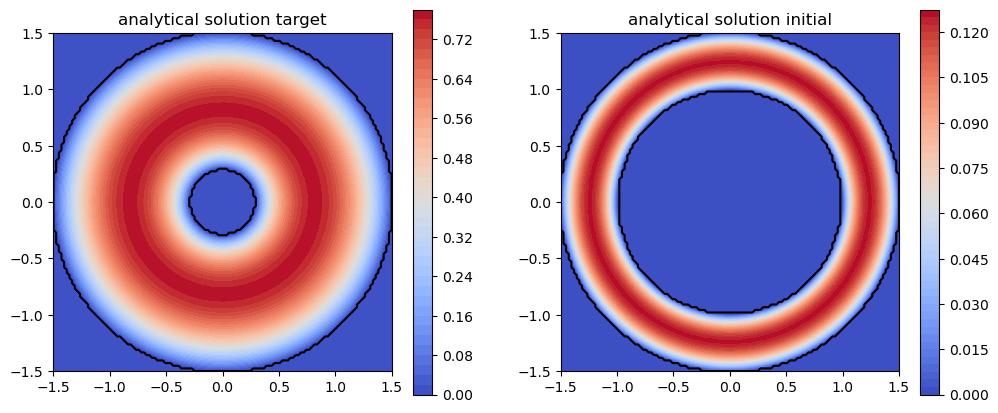

In [36]:
fig = plt.figure(figsize=(12, 5))

ax1 = fig.add_subplot(121)
contouf = ax1.contourf(X, Y, jax.vmap(lambda x: solution_analytical(0.3, 1.5, const_source_fn, x))(points).reshape(X.shape), levels=50, cmap='coolwarm')
contour = ax1.contour(X, Y, reference_estimate_full.reshape(X.shape), levels=[0.0], colors='k')
ax1.set_aspect('equal')
ax1.set_title('analytical solution target')
plt.colorbar(contouf)

ax2 = fig.add_subplot(122)
contouf2 = ax2.contourf(X, Y, jax.vmap(lambda x: solution_analytical(1.0, 1.5, const_source_fn, x))(points).reshape(X.shape), levels=50, cmap='coolwarm')
contour2 = ax2.contour(X, Y, init_estimate_full.reshape(X.shape), levels=[0.0], colors='k')
ax2.set_aspect('equal')
ax2.set_title('analytical solution initial')
plt.colorbar(contouf2)

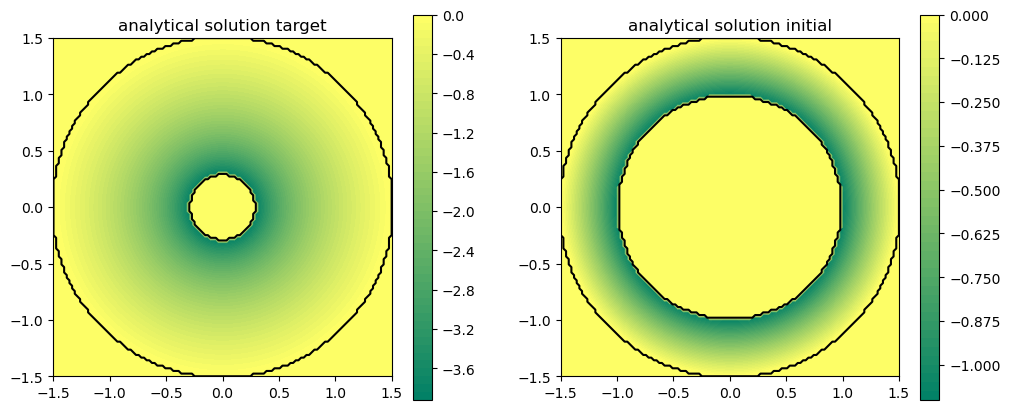

In [40]:
fig = plt.figure(figsize=(12, 5))

ax1 = fig.add_subplot(121)
contouf = ax1.contourf(X, Y, jax.vmap(lambda x: solution_Rmin_deriv(0.3, 1.5, const_source_fn, x))(points).reshape(X.shape), levels=50, cmap='summer')
contour = ax1.contour(X, Y, reference_estimate_full.reshape(X.shape), levels=[0.0], colors='k')
ax1.set_aspect('equal')
ax1.set_title('analytical solution target')
plt.colorbar(contouf)

ax2 = fig.add_subplot(122)
contouf2 = ax2.contourf(X, Y, jax.vmap(lambda x: solution_Rmin_deriv(1.0, 1.5, const_source_fn, x))(points).reshape(X.shape), levels=50, cmap='summer')
contour2 = ax2.contour(X, Y, init_estimate_full.reshape(X.shape), levels=[0.0], colors='k')
ax2.set_aspect('equal')
ax2.set_title('analytical solution initial')
plt.colorbar(contouf2)

In [45]:
R_vals = jnp.linspace(0.3001, 1.4999, 1000)
R_min_target = 0.3
R_max = 1.5
surface_contribs = jax.vmap(lambda R: surface_integral_unnormalized(R, R_min_target, R_max, const_source_fn))(R_vals)
volume_contribs = jax.vmap(lambda R: volume_integral_unnormalized(R, R_min_target, R_max, const_source_fn))(R_vals)

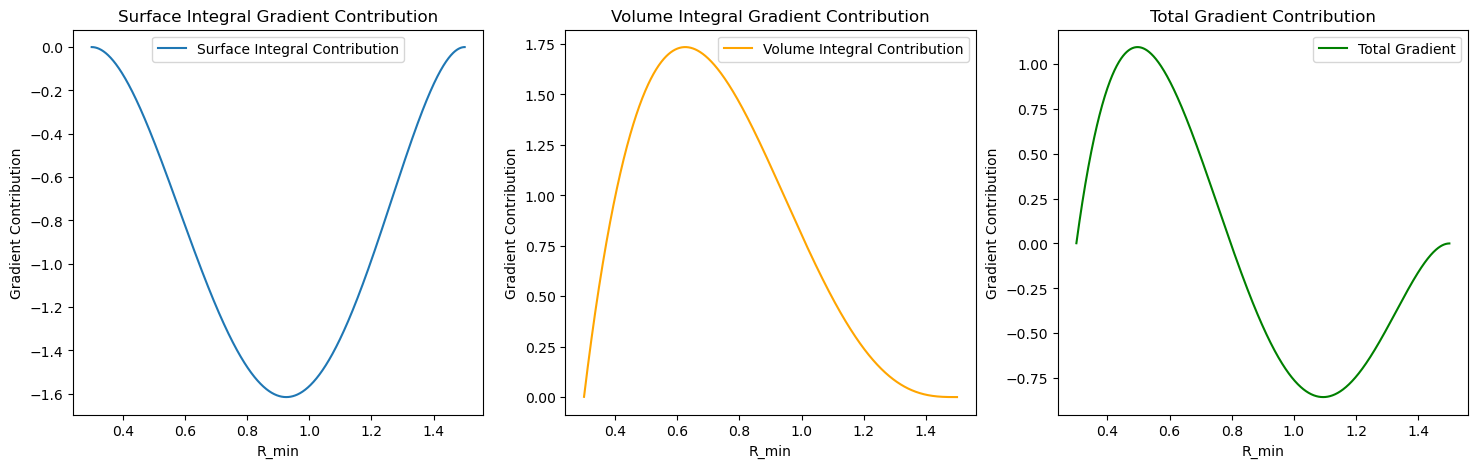

In [48]:
fig = plt.figure(figsize=(18, 5))

ax1 = fig.add_subplot(131)
ax1.plot(R_vals, surface_contribs, label='Surface Integral Contribution')
ax1.set_title('Surface Integral Gradient Contribution')
ax1.set_xlabel('R_min')
ax1.set_ylabel('Gradient Contribution')
ax1.legend()

ax2 = fig.add_subplot(132)
ax2.plot(R_vals, volume_contribs, label='Volume Integral Contribution', color='orange')
ax2.set_title('Volume Integral Gradient Contribution')
ax2.set_xlabel('R_min')
ax2.set_ylabel('Gradient Contribution')
ax2.legend()

ax3 = fig.add_subplot(133)
ax3.plot(R_vals, surface_contribs + volume_contribs, label='Total Gradient', color='green')
ax3.set_title('Total Gradient Contribution')
ax3.set_xlabel('R_min')
ax3.set_ylabel('Gradient Contribution')
ax3.legend()

plt.show()

##### Normalization

change loss

$J_{\Omega} = \frac{1}{|\Omega|} \int_{\Omega} \frac{1}{2} (u(R_{min}, x) - u_{target}(x))^2 dV$

In [54]:
R_vals = jnp.linspace(0.3001, 1.4999, 1000)
R_min_target = 0.3
R_max = 1.5
surface_contribs_norm = jax.vmap(lambda R: surface_integral_normalized(R, R_min_target, R_max, const_source_fn))(R_vals)
volume_contribs_norm = jax.vmap(lambda R: volume_integral_normalized(R, R_min_target, R_max, const_source_fn))(R_vals)

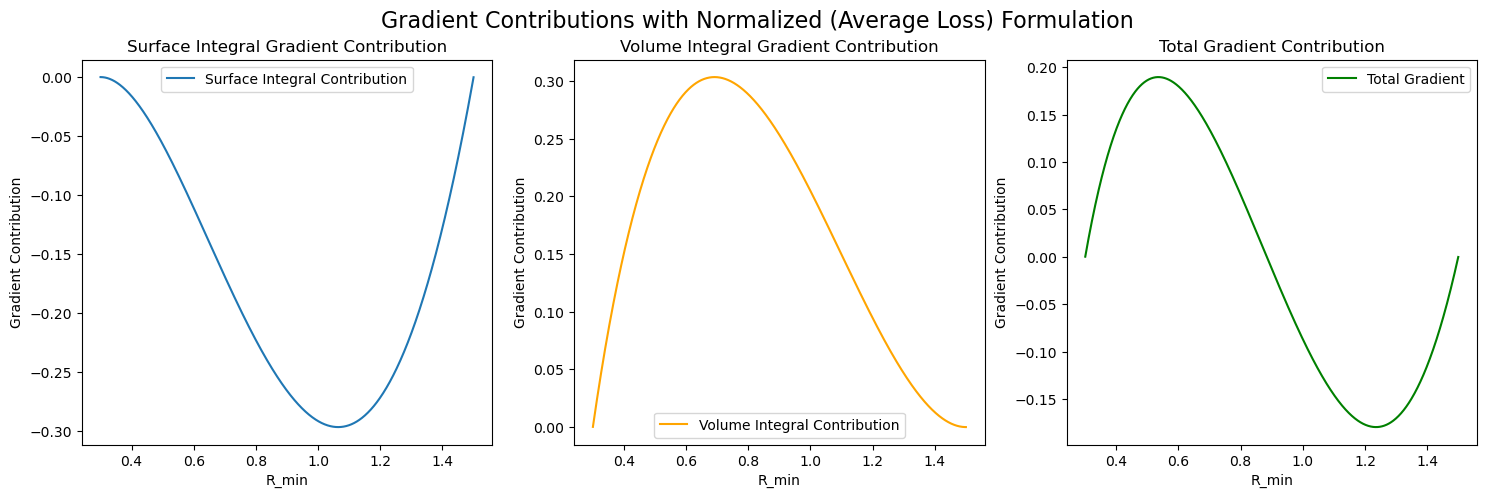

In [56]:
fig = plt.figure(figsize=(18, 5))
fig.suptitle('Gradient Contributions with Normalized (Average Loss) Formulation', fontsize=16)

ax1 = fig.add_subplot(131)
ax1.plot(R_vals, surface_contribs_norm, label='Surface Integral Contribution')
ax1.set_title('Surface Integral Gradient Contribution')
ax1.set_xlabel('R_min')
ax1.set_ylabel('Gradient Contribution')
ax1.legend()

ax2 = fig.add_subplot(132)
ax2.plot(R_vals, volume_contribs_norm, label='Volume Integral Contribution', color='orange')
ax2.set_title('Volume Integral Gradient Contribution')
ax2.set_xlabel('R_min')
ax2.set_ylabel('Gradient Contribution')
ax2.legend()

ax3 = fig.add_subplot(133)
ax3.plot(R_vals, surface_contribs_norm + volume_contribs_norm, label='Total Gradient', color='green')
ax3.set_title('Total Gradient Contribution')
ax3.set_xlabel('R_min')
ax3.set_ylabel('Gradient Contribution')
ax3.legend()

plt.show()